# Dot Strip Plot (rank position)

**Family:** Ranking &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Ranking:* Use when an item's position in an ordered list matters more than its absolute value.

## Design purpose

Places every item as a dot along a single value axis, one strip per group, with the item of interest highlighted. It shows where one entity ranks within each of several measures.

## When to use

- Show where one item (your city, your product) ranks across several metrics
- Show a ranking where the spread of the whole field matters too

## Avoid when

- There are no items worth highlighting (a box plot summarises spread better)
- There are thousands of items per strip (dots merge)

## Alternatives

- Beeswarm plot
- Small-multiple ordered bars

## Example

Scores of 30 cities on five liveability measures; 'Our city' is highlighted.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(2)
metrics = ["Safety", "Healthcare", "Education", "Housing cost", "Transit"]
cities = [f"City {i}" for i in range(29)] + ["Our city"]
rows = [(c, m, rng.uniform(30, 95)) for c in cities for m in metrics]
df = pd.DataFrame(rows, columns=["city", "metric", "score"])
ours = {"Safety": 88, "Healthcare": 74, "Education": 52, "Housing cost": 35, "Transit": 81}
df.loc[df["city"] == "Our city", "score"] = df.loc[df["city"] == "Our city", "metric"].map(ours)
df["rank"] = df.groupby("metric")["score"].rank(ascending=False).astype(int)
df[df["city"] == "Our city"]

,city,metric,score,rank
145,Our city,Safety,88.0,6
146,Our city,Healthcare,74.0,8
147,Our city,Education,52.0,22
148,Our city,Housing cost,35.0,28
149,Our city,Transit,81.0,4


### Plot

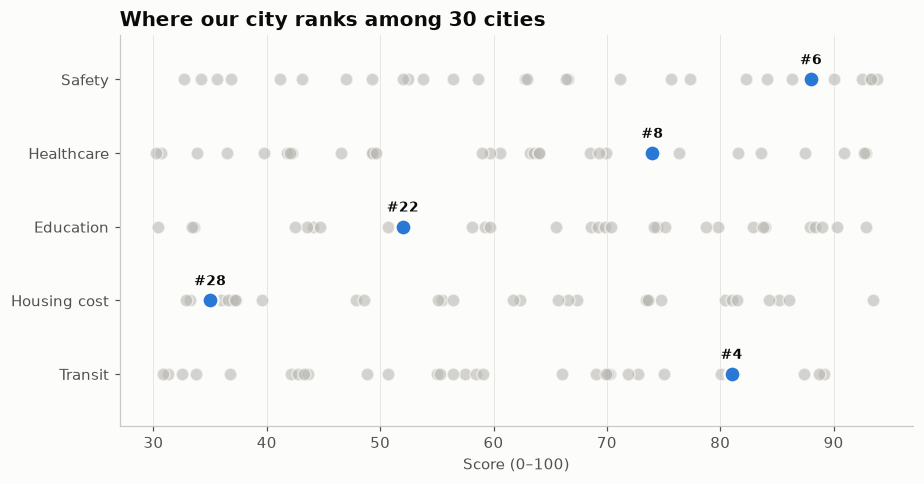

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
for y, m in enumerate(metrics):
    g = df[df["metric"] == m]
    others = g[g["city"] != "Our city"]
    ax.scatter(others["score"], np.full(len(others), y), s=70, color=GRAY, alpha=0.6,
               edgecolor="#fcfcfb", linewidth=1)
    me = g[g["city"] == "Our city"].iloc[0]
    ax.scatter(me["score"], y, s=110, color=PALETTE[0], zorder=3, edgecolor="#fcfcfb", linewidth=1.5)
    ax.annotate(f"#{me['rank']}", (me["score"], y), xytext=(0, 10), textcoords="offset points",
                ha="center", fontsize=9, color="#0b0b0b", weight="bold")
ax.set_yticks(range(len(metrics)), metrics)
ax.set_ylim(-0.6, len(metrics) - 0.3)
ax.invert_yaxis()
ax.set_xlabel("Score (0–100)")
ax.set_title("Where our city ranks among 30 cities")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

## How to read it

Each gray dot is another city and the blue dot is ours, labelled with its rank. We lead on safety but sit near the bottom on housing cost.

---
Standalone script: [`dot_strip_plot.py`](dot_strip_plot.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)